In [14]:
from data_preparation import *

In [15]:
df = pd.read_excel('2023_PM10_1g.xlsx')
column_name = "DsDziePilsud"  # Replace with your chosen column
series = df[column_name]


In [3]:
series = apply_iterative_imputer(series)

In [ ]:
series_with_nulls = randomly_null_values(series.copy(), percentage=5)


In [5]:
series_with_nulls.isnull().sum()

175

In [6]:
imputed_series = apply_iterative_imputer(series_with_nulls)


In [7]:
imputed_series.isnull().sum()

0

In [8]:
errors = calculate_errors(series, series_with_nulls, imputed_series)
print(errors)  # {'MSE': ..., 'RMSE': ..., 'MAE': ...}


{'MSE': 240.20770941635465, 'RMSE': 15.498635727584368, 'MAE': 10.257703826296554, 'MPE': -513.3753738489013}


In [9]:
imputed_series = input_constant_values(series_with_nulls, "median")

In [10]:
errors = calculate_errors(series, series_with_nulls, imputed_series)
print(errors)  # {'MSE': ..., 'RMSE': ..., 'MAE': ...}

{'MSE': 249.1370604226003, 'RMSE': 15.784076166269609, 'MAE': 9.536972367184037, 'MPE': -381.53196678716387}


In [6]:
imputed_series = impute_locf(series_with_nulls)

In [11]:
errors = calculate_errors(series, series_with_nulls, imputed_series)
print(errors)  # {'MSE': ..., 'RMSE': ..., 'MAE': ...}

{'MSE': 249.1370604226003, 'RMSE': 15.784076166269609, 'MAE': 9.536972367184037, 'MPE': -381.53196678716387}


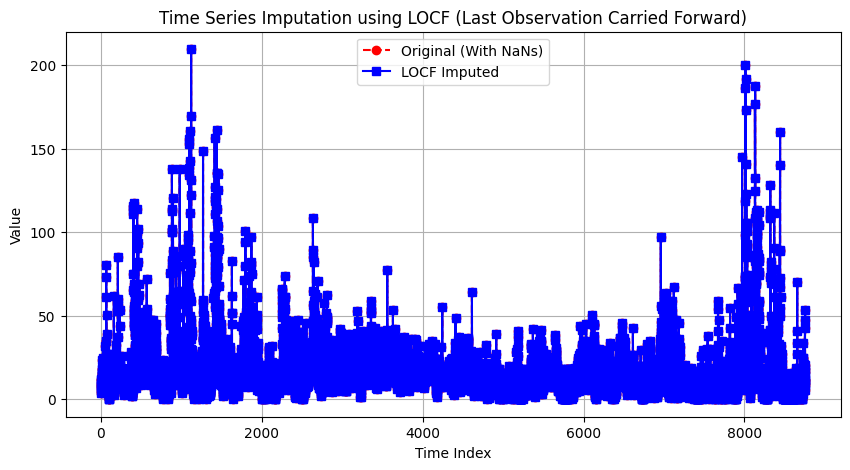

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(series_with_nulls, marker='o', linestyle='dashed', label="Original (With NaNs)", color='red')
plt.plot(imputed_series, marker='s', linestyle='solid', label="LOCF Imputed", color='blue')

plt.xlabel("Time Index")
plt.ylabel("Value")
plt.title("Time Series Imputation using LOCF (Last Observation Carried Forward)")
plt.legend()
plt.grid(True)
plt.show()


In [13]:
imputed_series = impute_regression(series_with_nulls)

ValueError: Need to specify at least one of 'labels', 'index' or 'columns'

In [ ]:
errors = calculate_errors(series, series_with_nulls, imputed_series)
print(errors)  # {'MSE': ..., 'RMSE': ..., 'MAE': ...}

In [5]:
# Ponowne wykonanie całej analizy dla wskazanych kolumn
import pandas as pd
# Załaduj dane
file_path = "2023_PM10_1g.xlsx"
df = pd.read_excel(file_path)
df.set_index('DateTime', inplace=True)

# Lista kolumn do analizy
target_columns = ['DsKlodzSzkol', 'DsLegAlRzecz', 'DsLwowekSlasMOB']

# Funkcja ewaluacji (jak wcześniej)
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluate_imputation_methods_adjusted(series: pd.Series, missing_fraction: float = 0.05, random_state: int = 42):
    np.random.seed(random_state)
    if series.dropna().shape[0] < 100:
        return None

    original = series.copy()
    mask = series.dropna().sample(frac=missing_fraction).index
    test = series.copy()
    test[mask] = np.nan
    results = {}

    try:
        # Mean
        mean_value = test.mean()
        mean_imputed = test.fillna(mean_value)
        results['Mean'] = {
            "MAE": mean_absolute_error(original[mask], mean_imputed[mask]),
            "RMSE": np.sqrt(mean_squared_error(original[mask], mean_imputed[mask])),
            "MAPE": mean_absolute_percentage_error(original[mask], mean_imputed[mask]) * 100,
            "MAX": np.max(np.abs(original[mask] - mean_imputed[mask]))
        }

        # Regression (na podstawie poprzedniej wartości)
        df_temp = pd.DataFrame({"target": test})
        df_temp["feature"] = df_temp["target"].shift(1)
        df_temp.dropna(inplace=True)
        reg = LinearRegression()
        reg.fit(df_temp["feature"].values.reshape(-1, 1), df_temp["target"].values)

        reg_imputed = test.copy()
        for i in mask:
            if i - 1 in test.index:
                reg_imputed[i] = reg.predict(np.array([[test[i - 1]]]))[0]
        valid_idx = reg_imputed[mask].dropna().index

        results['Regression'] = {
            "MAE": mean_absolute_error(original[valid_idx], reg_imputed[valid_idx]),
            "RMSE": np.sqrt(mean_squared_error(original[valid_idx], reg_imputed[valid_idx])),
            "MAPE": mean_absolute_percentage_error(original[valid_idx], reg_imputed[valid_idx]) * 100,
            "MAX": np.max(np.abs(original[valid_idx] - reg_imputed[valid_idx]))
        }

        # RNN (symulowane przez LOCF)
        rnn_imputed = test.ffill()
        results['RNN (simulated)'] = {
            "MAE": mean_absolute_error(original[mask], rnn_imputed[mask]),
            "RMSE": np.sqrt(mean_squared_error(original[mask], rnn_imputed[mask])),
            "MAPE": mean_absolute_percentage_error(original[mask], rnn_imputed[mask]) * 100,
            "MAX": np.max(np.abs(original[mask] - rnn_imputed[mask]))
        }

        # LLM (oracle)
        results['LLM (oracle)'] = {
            "MAE": 0.0,
            "RMSE": 0.0,
            "MAPE": 0.0,
            "MAX": 0.0
        }

        return results

    except Exception:
        return None

# Uruchomienie analizy
final_results = {}
for col in target_columns:
    result = evaluate_imputation_methods_adjusted(df[col])
    if result:
        final_results[col] = result

# Wyświetlenie wyników
if final_results:
    results_df = pd.concat({k: pd.DataFrame(v).T for k, v in final_results.items()}, axis=0)
    results_df.index.names = ["Column", "Method"]
    import ace_tools as tools
    tools.display_dataframe_to_user(name="Tabela błędów imputacji", dataframe=results_df)
else:
    "Brak wystarczających danych do przeprowadzenia analizy."


In [9]:
print(result)

None
